# Fashion-MNIST ile Kıyafet Görüntülerinin Sınıflandırılması
**Makine Öğrenmesi ile Probleme Uygun Çözüm Geliştirme — derin öğrenme projesi**

Bu çalışma yalnızca bir CNN eğitmekle kalmaz: klasik ML taban çizgileri (Logistic Regression, Random Forest), tam bağlantılı ağ (MLP), CNN ve veri artırmalı CNN'i **aynı bölünmede** karşılaştırır; 3 farklı rastgele tohumla tekrar eder, McNemar testiyle farkın anlamlılığını sınar, olasılık kalibrasyonunu (ECE, sıcaklık ölçekleme) ölçer ve Grad-CAM ile hataları görsel olarak inceler.

**Veri kaynağı:** Zalando Research, Fashion-MNIST (MIT lisansı) — https://github.com/zalandoresearch/fashion-mnist (Keras üzerinden yüklenir).

## 1. Problem Tanımı
Bir e-ticaret platformunda ürün görsellerinin kategoriye otomatik atanması istenir. **Girdi:** 28×28 gri tonlamalı kıyafet görüntüsü. **Çıktı:** 10 sınıftan biri. **İhtiyaç:** Elle etiketleme maliyetini azaltmak; özellikle birbirine benzeyen sınıflarda (gömlek / tişört / kazak / ceket) hatanın nerede ve neden olduğunu bilmek.

In [1]:
import os, json, time, warnings; warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf, keras
from keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
sns.set_theme(style="whitegrid"); os.makedirs("figures", exist_ok=True)
M = {}   # sayısal sonuçlar -> metrics.json
SINIF = ["Tişört/Üst", "Pantolon", "Kazak", "Elbise", "Ceket", "Sandalet", "Gömlek", "Spor ayakkabı", "Çanta", "Bilek botu"]
(Xtr_all, ytr_all), (Xte, yte) = keras.datasets.fashion_mnist.load_data()
print(Xtr_all.shape, Xte.shape, Xtr_all.dtype, Xtr_all.min(), Xtr_all.max())

(60000, 28, 28) (10000, 28, 28) uint8 0 255


## 2. Veri Seti
60.000 eğitim + 10.000 test görüntüsü, 10 sınıf; sınıflar **tam dengelidir** (her sınıfta eğitimde 6.000, testte 1.000). Eksik değer yoktur. Eğitim verisinden **%10 doğrulama** kümesi (stratified) ayrılır; test seti yalnızca final değerlendirmede kullanılır.

In [2]:
print(pd.Series(ytr_all).value_counts().sort_index().rename(dict(enumerate(SINIF))).to_frame("eğitim örneği").T)
Xtr, Xva, ytr, yva = train_test_split(Xtr_all, ytr_all, test_size=0.1, random_state=0, stratify=ytr_all)
print("Eğitim:", Xtr.shape, "Doğrulama:", Xva.shape, "Test:", Xte.shape)
M["n_train"], M["n_val"], M["n_test"] = len(Xtr), len(Xva), len(Xte)

               Tişört/Üst  Pantolon  Kazak  Elbise  Ceket  Sandalet  Gömlek  \
eğitim örneği        6000      6000   6000    6000   6000      6000    6000   

               Spor ayakkabı  Çanta  Bilek botu  
eğitim örneği           6000   6000        6000  
Eğitim: (54000, 28, 28) Doğrulama: (6000, 28, 28) Test: (10000, 28, 28)


## 3. Veri Keşfi (3 görselleştirme)

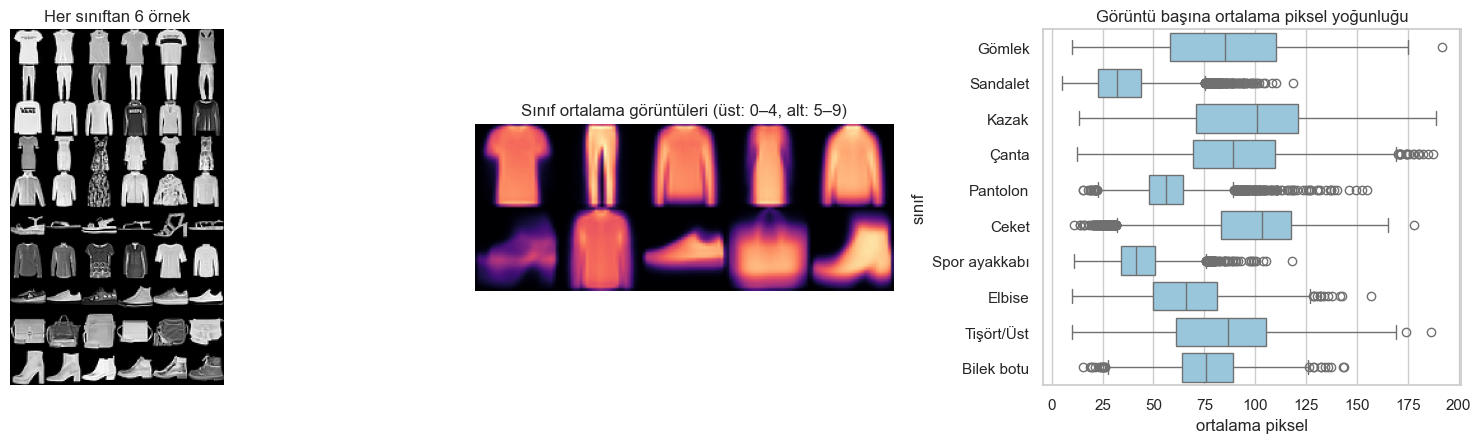

In [3]:
fig = plt.figure(figsize=(16, 4.6))
ax = fig.add_subplot(1, 3, 1); ax.axis("off"); ax.set_title("Her sınıftan 6 örnek")
grid = np.vstack([np.hstack([Xtr[ytr == k][i] for i in range(6)]) for k in range(10)]); ax.imshow(grid, cmap="gray")
ax2 = fig.add_subplot(1, 3, 2); ort = np.vstack([np.hstack([Xtr[ytr == k].mean(0) for k in range(5)]), np.hstack([Xtr[ytr == k].mean(0) for k in range(5, 10)])])
ax2.imshow(ort, cmap="magma"); ax2.axis("off"); ax2.set_title("Sınıf ortalama görüntüleri (üst: 0–4, alt: 5–9)")
ax3 = fig.add_subplot(1, 3, 3); parlak = pd.DataFrame({"sınıf": [SINIF[k] for k in ytr], "ortalama piksel": Xtr.reshape(len(Xtr), -1).mean(1)})
sns.boxplot(data=parlak, y="sınıf", x="ortalama piksel", ax=ax3, color="#8ecae6"); ax3.set_title("Görüntü başına ortalama piksel yoğunluğu")
plt.tight_layout(); plt.savefig("figures/eda.png", dpi=150); plt.show()

**Gözlemler.** (1) Ayakkabı sınıfları (sandalet, spor ayakkabı, bilek botu) ve çanta kolay ayrışır; üst giyim sınıfları (tişört, kazak, ceket, gömlek) ortalama görüntülerde birbirine çok benzer. (2) Pantolon ve elbise belirgin silüetlere sahiptir. (3) Ortalama piksel yoğunluğu sınıflar arasında büyük ölçüde örtüşür, bu yüzden tek başına ayırt edici değildir → **şekil/doku** öğrenen bir modele ihtiyaç var.

## 4. Veri Ön İşleme
- **Normalizasyon:** Pikseller 0–255 → 0–1 aralığına çekilir.
- **Yeniden boyutlandırma:** Gerekmez (28×28); CNN için kanal ekseni eklenir `(28, 28, 1)`.
- **Veri artırma (yalnızca eğitim sırasında, modelin içinde):** ±%8 öteleme, ±%5 dönme, ±%8 yakınlaştırma, yatay çevirme. Giyim ürünlerinde yatay simetri anlamı değiştirmez; dikey çevirme **kullanılmaz** (ters elbise gerçekçi değildir).
- **Etiket:** Sınıflar tamsayı etiketli, kayıp: `sparse_categorical_crossentropy`.

In [4]:
f = lambda a: (a.astype("float32") / 255.0)[..., None]
Xtr_n, Xva_n, Xte_n = f(Xtr), f(Xva), f(Xte)
Xtr_f, Xva_f, Xte_f = [a.reshape(len(a), -1) for a in (Xtr_n, Xva_n, Xte_n)]
print(Xtr_n.shape, Xtr_n.max())

(54000, 28, 28, 1) 1.0


## 5. Model Seçimi / Tasarımı
| Model | Neden? |
|---|---|
| Logistic Regression (piksel) | Doğrusal taban çizgisi |
| Random Forest (piksel) | Doğrusal olmayan klasik ML taban çizgisi |
| MLP (512-256) | Mekânsal yapıyı kullanmayan derin ağ |
| **CNN** (3 blok: 2×Conv3×3 + BatchNorm + ReLU + MaxPool + Dropout; GlobalAveragePooling; softmax-10) | Kenar/doku/şekil örüntüleri; parametre verimli |
| **CNN + veri artırma** | Aşırı öğrenmeyi azaltma (daha uzun eğitim gerektirir) |

**Mimari seçimleri:** Conv3×3 (küçük alıcı alan, derinlikle büyür), BatchNorm (kararlı ve hızlı eğitim), ReLU, MaxPool(2) (boyut azaltma), Dropout(0,25/0,35) (düzenlileştirme), çıkışta 10 nöron + softmax (çok sınıflı olasılık). **Kayıp:** sparse categorical cross-entropy. **Optimizer:** Adam (lr 1e-3, `ReduceLROnPlateau`).

In [5]:
def seed_all(s): keras.utils.set_random_seed(s)
def conv_blok(x, f, drop, ad):
    for i in (1, 2):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False, name=f"{ad}_conv{i}")(x)
        x = layers.BatchNormalization(name=f"{ad}_bn{i}")(x); x = layers.Activation("relu", name=f"{ad}_relu{i}")(x)
    return layers.Dropout(drop)(layers.MaxPooling2D(2)(x))
def cnn_olustur(aug):
    giris = keras.Input((28, 28, 1)); x = giris
    if aug:
        x = layers.RandomTranslation(0.08, 0.08)(x); x = layers.RandomRotation(0.05)(x); x = layers.RandomZoom(0.08)(x); x = layers.RandomFlip("horizontal")(x)
    x = conv_blok(x, 24, .25, "b1"); x = conv_blok(x, 48, .25, "b2"); x = conv_blok(x, 64, .3, "b3")
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(.35)(x)
    return keras.Model(giris, layers.Dense(10, activation="softmax")(x))
def mlp_olustur():
    return keras.Sequential([keras.Input((784,)), layers.Dense(512, activation="relu"), layers.Dropout(.3), layers.Dense(256, activation="relu"), layers.Dropout(.3), layers.Dense(10, activation="softmax")])
cnn_olustur(True).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv1 (Conv2D)               │ (None, 28, 28, 24)     │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn1 (BatchNormalization)     │ (None, 28, 28, 24)     │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu1 (Activation)           │ (None, 28, 28, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv2 (Conv2D)               │ (None, 28, 28, 24)     │         5,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn2 (BatchNormalization)     │ (None, 28, 28, 24)     │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu2 (Activation)           │ (None, 28, 28, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv1 (Conv2D)               │ (None, 14, 14, 48)     │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn1 (BatchNormalization)     │ (None, 14, 14, 48)     │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu1 (Activation)           │ (None, 14, 14, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv2 (Conv2D)               │ (None, 14, 14, 48)     │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn2 (BatchNormalization)     │ (None, 14, 14, 48)     │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu2 (Activation)           │ (None, 14, 14, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 48)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 48)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv1 (Conv2D)               │ (None, 7, 7, 64)       │        27,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn1 (BatchNormalization)     │ (None, 7, 7, 64)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu1 (Activation)           │ (None, 7, 7, 64)       │             

 Total params: 102,754 (401.38 KB)

 Trainable params: 102,210 (399.26 KB)

 Non-trainable params: 544 (2.12 KB)

## 6. Model Eğitimi
- **Doğrulama yaklaşımı:** Eğitimden ayrılan %10'luk sabit doğrulama kümesi; `EarlyStopping(patience=3, restore_best_weights=True)`.
- **Epoch / batch size:** En fazla 8 epoch (veri artırmalı model için 16; CPU süresi nedeniyle kısa tutuldu), batch size 128.
- Tüm derin modeller **3 farklı tohumla (0, 1, 2)** eğitilir; sonuçlar ortalama ± standart sapma olarak raporlanır.
- Klasik ML taban çizgileri varsayılana yakın ayarlarla bir kez eğitilir (hiperparametre ayarı yapılmadı; bu taban çizgisi için bilinçli bir sadelik).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
SONUC = {}; TAHMIN = {}; GECMIS = {}
t0 = time.time(); lr = LogisticRegression(max_iter=200).fit(Xtr_f, ytr); TAHMIN["Logistic Regression"] = lr.predict_proba(Xte_f); print("LR", round(time.time() - t0), "sn")
t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0).fit(Xtr_f, ytr); TAHMIN["Random Forest"] = rf.predict_proba(Xte_f); print("RF", round(time.time() - t0), "sn")
def egit(kurucu, X1, X2, ad, tohum, epochs=None):
    epochs = epochs or (16 if "artırma" in ad else 8)   # artırma daha uzun eğitim ister
    seed_all(tohum); mdl = kurucu(); mdl.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor="val_loss"), keras.callbacks.ReduceLROnPlateau(factor=.5, patience=2, min_lr=1e-5)]
    t0 = time.time(); h = mdl.fit(X1, ytr, validation_data=(X2, yva), epochs=epochs, batch_size=128, callbacks=cb, verbose=0)
    print(f"{ad} (tohum {tohum}): {len(h.history['loss'])} epoch, {time.time() - t0:.0f} sn, val_acc={max(h.history['val_accuracy']):.4f}")
    return mdl, h.history
MODELLER = {}
for ad, kur, a1, a2 in [("MLP", mlp_olustur, Xtr_f, Xva_f), ("CNN", lambda: cnn_olustur(False), Xtr_n, Xva_n), ("CNN + veri artırma", lambda: cnn_olustur(True), Xtr_n, Xva_n)]:
    MODELLER[ad] = []
    for tohum in (0, 1, 2):
        mdl, h = egit(kur, a1, a2, ad, tohum); MODELLER[ad].append(mdl); GECMIS.setdefault(ad, []).append(h)

LR 10 sn


RF 15 sn


MLP (tohum 0): 8 epoch, 16 sn, val_acc=0.8865


MLP (tohum 1): 8 epoch, 15 sn, val_acc=0.8885


MLP (tohum 2): 8 epoch, 15 sn, val_acc=0.8885


CNN (tohum 0): 8 epoch, 157 sn, val_acc=0.9122


CNN (tohum 1): 8 epoch, 157 sn, val_acc=0.9183


CNN (tohum 2): 8 epoch, 157 sn, val_acc=0.9178


CNN + veri artırma (tohum 0): 16 epoch, 384 sn, val_acc=0.9052


CNN + veri artırma (tohum 1): 14 epoch, 339 sn, val_acc=0.8938


CNN + veri artırma (tohum 2): 14 epoch, 359 sn, val_acc=0.8927


## 7. Model Değerlendirme (test kümesi)

In [7]:
def tahmin(mdl, ad):
    return mdl.predict(Xte_f if ad == "MLP" else Xte_n, batch_size=512, verbose=0)
rows = []
for ad in ["Logistic Regression", "Random Forest"]:
    p = TAHMIN[ad].argmax(1); pr, rc, f1, _ = precision_recall_fscore_support(yte, p, average="macro")
    rows.append(dict(Model=ad, Accuracy=accuracy_score(yte, p), Precision=pr, Recall=rc, F1=f1, Std=0.0))
for ad, mdls in MODELLER.items():
    olasi = [tahmin(m_, ad) for m_ in mdls]; accs = [accuracy_score(yte, o.argmax(1)) for o in olasi]
    TAHMIN[ad] = olasi[int(np.argmax(accs))]          # grafikler için en iyi tohum
    TAHMIN[ad + "|hepsi"] = olasi
    ps = [precision_recall_fscore_support(yte, o.argmax(1), average="macro")[:3] for o in olasi]
    rows.append(dict(Model=ad, Accuracy=np.mean(accs), Precision=np.mean([p[0] for p in ps]), Recall=np.mean([p[1] for p in ps]), F1=np.mean([p[2] for p in ps]), Std=np.std(accs)))
tablo = pd.DataFrame(rows).set_index("Model"); display(tablo.round(4)); M["tablo"] = tablo.round(4).reset_index().to_dict("records")

,Accuracy,Precision,Recall,F1,Std
Model,,,,,
Logistic Regression,0.8452,0.8438,0.8452,0.8442,0.0000
Random Forest,0.8754,0.8743,0.8754,0.8739,0.0000
MLP,0.8797,0.8800,0.8797,0.8790,0.0009
CNN,0.9083,0.9100,0.9083,0.9079,0.0019
CNN + veri artırma,0.8883,0.8893,0.8883,0.8880,0.0032


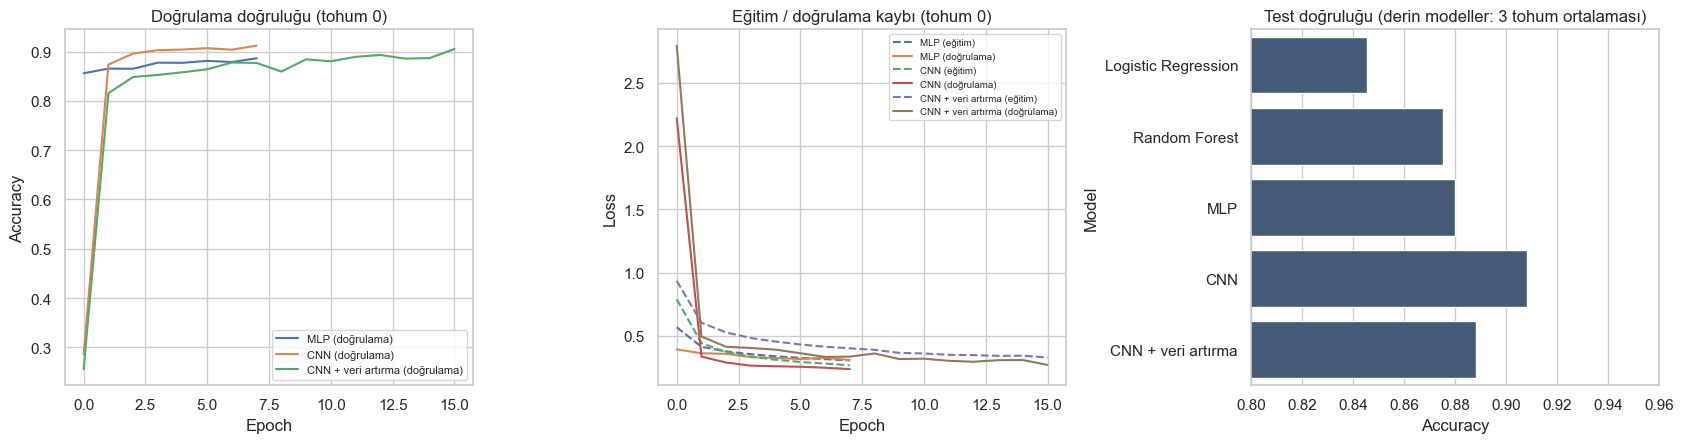

{'CNN': {'son_egitim_acc': 0.9044444561004639, 'son_val_acc': 0.9121666550636292}, 'CNN + veri artırma': {'son_egitim_acc': 0.8814073801040649, 'son_val_acc': 0.9051666855812073}}


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for i, ad in enumerate(["MLP", "CNN", "CNN + veri artırma"]):
    h = GECMIS[ad][0]; ax[0].plot(h["val_accuracy"], label=f"{ad} (doğrulama)"); ax[1].plot(h["loss"], "--", label=f"{ad} (eğitim)"); ax[1].plot(h["val_loss"], label=f"{ad} (doğrulama)")
ax[0].set_title("Doğrulama doğruluğu (tohum 0)"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend(fontsize=8)
ax[1].set_title("Eğitim / doğrulama kaybı (tohum 0)"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend(fontsize=7)
sns.barplot(data=tablo.reset_index(), y="Model", x="Accuracy", ax=ax[2], color="#3d5a80"); ax[2].set_xlim(.8, .96); ax[2].set_title("Test doğruluğu (derin modeller: 3 tohum ortalaması)")
plt.tight_layout(); plt.savefig("figures/egitim_ve_karsilastirma.png", dpi=150); plt.show()
h0 = GECMIS["CNN"][0]; h1 = GECMIS["CNN + veri artırma"][0]
M["gecmis"] = {"CNN": {"son_egitim_acc": h0["accuracy"][-1], "son_val_acc": h0["val_accuracy"][-1]}, "CNN + veri artırma": {"son_egitim_acc": h1["accuracy"][-1], "son_val_acc": h1["val_accuracy"][-1]}}
print(M["gecmis"])

Analiz edilen en iyi model: CNN
               precision    recall  f1-score   support

   Tişört/Üst      0.864     0.874     0.869      1000
     Pantolon      0.997     0.978     0.987      1000
        Kazak      0.833     0.916     0.873      1000
       Elbise      0.914     0.908     0.911      1000
        Ceket      0.852     0.872     0.862      1000
     Sandalet      0.997     0.958     0.977      1000
       Gömlek      0.807     0.688     0.743      1000
Spor ayakkabı      0.915     0.991     0.952      1000
        Çanta      0.953     0.993     0.973      1000
   Bilek botu      0.978     0.932     0.954      1000

     accuracy                          0.911     10000
    macro avg      0.911     0.911     0.910     10000
 weighted avg      0.911     0.911     0.910     10000



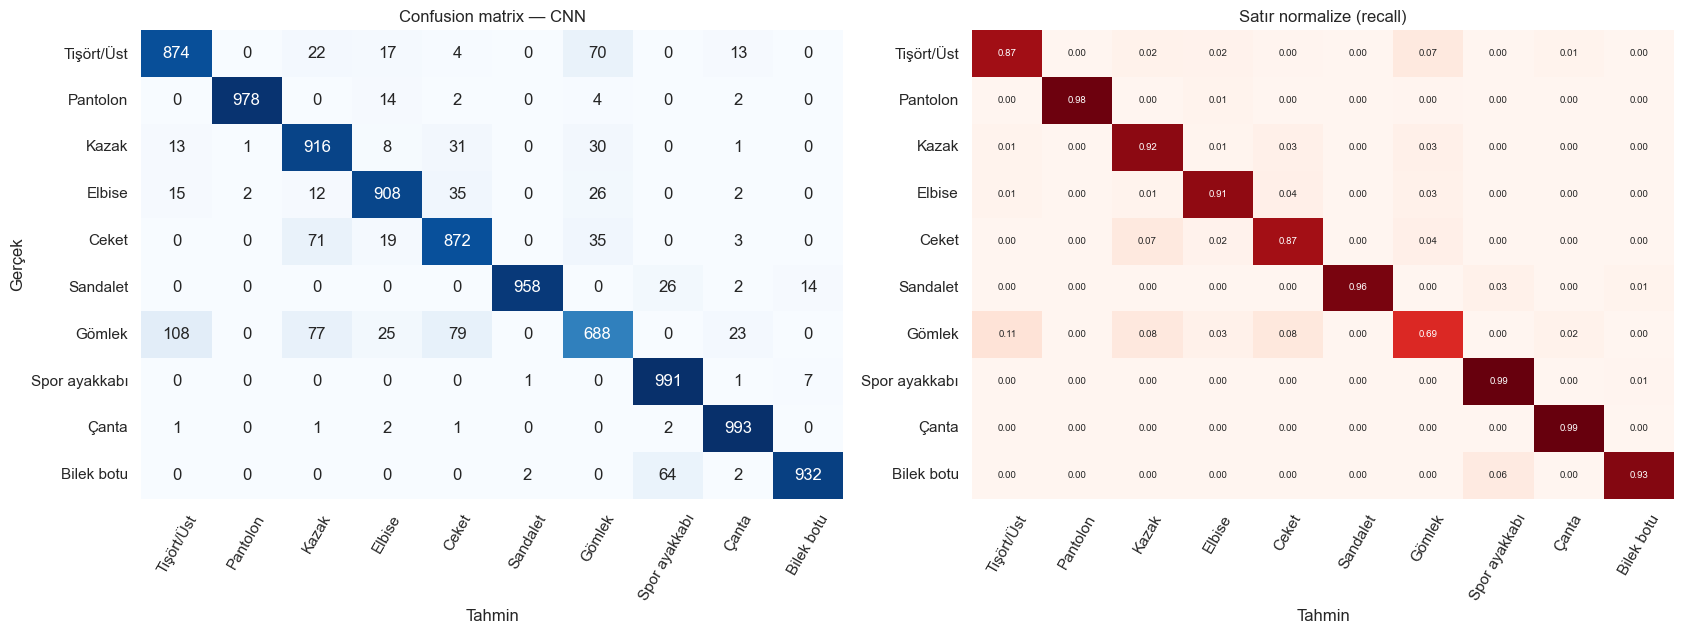

En sık karışan çiftler: [(np.int64(108), 'Gömlek', 'Tişört/Üst'), (np.int64(79), 'Gömlek', 'Ceket'), (np.int64(77), 'Gömlek', 'Kazak'), (np.int64(71), 'Ceket', 'Kazak'), (np.int64(70), 'Tişört/Üst', 'Gömlek'), (np.int64(64), 'Bilek botu', 'Spor ayakkabı')]


In [9]:
EN = max(["MLP", "CNN", "CNN + veri artırma"], key=lambda k: tablo.loc[k, "Accuracy"]); M["en_iyi_model"] = EN; print("Analiz edilen en iyi model:", EN); p_en = TAHMIN[EN].argmax(1)
print(classification_report(yte, p_en, target_names=SINIF, digits=3))
M["rapor"] = classification_report(yte, p_en, target_names=SINIF, output_dict=True)
cm = confusion_matrix(yte, p_en); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=SINIF, yticklabels=SINIF, ax=ax[0], cbar=False); ax[0].set_title(f"Confusion matrix — {EN}"); ax[0].set_xlabel("Tahmin"); ax[0].set_ylabel("Gerçek")
sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Reds", xticklabels=SINIF, yticklabels=SINIF, ax=ax[1], cbar=False, annot_kws={"size": 7}); ax[1].set_title("Satır normalize (recall)"); ax[1].set_xlabel("Tahmin")
for a in ax: a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig("figures/confusion.png", dpi=150); plt.show()
off = [(cm[i, j], SINIF[i], SINIF[j]) for i in range(10) for j in range(10) if i != j]; off.sort(reverse=True)
print("En sık karışan çiftler:", off[:6]); M["en_sik_karisan"] = [(int(a), b, c_) for a, b, c_ in off[:6]]

## 8. İstatistiksel Anlamlılık: CNN mi, CNN + veri artırma mı?
Aynı test örneklerinde iki modelin **eşleştirilmiş** hata karşılaştırması için McNemar testi (tam iki terimli) kullanılır. Yalnızca birinin doğru bildiği örnekler (uyuşmazlık) önemlidir.

In [10]:
from scipy.stats import binomtest
a = TAHMIN["CNN"].argmax(1) == yte; b = TAHMIN["CNN + veri artırma"].argmax(1) == yte
b10, b01 = int((a & ~b).sum()), int((~a & b).sum()); pval = binomtest(b10, b10 + b01, 0.5).pvalue
print(f"Sadece CNN doğru: {b10} | Sadece CNN+artırma doğru: {b01} | McNemar p = {pval:.4f}")
M["mcnemar"] = dict(sadece_cnn=b10, sadece_aug=b01, p=float(pval))

Sadece CNN doğru: 445 | Sadece CNN+artırma doğru: 263 | McNemar p = 0.0000


## 9. Olasılık Kalibrasyonu
Ürün kategorizasyonunda düşük güvenli tahminleri insan incelemesine yönlendirmek için olasılıkların **güvenilir** olması gerekir. ECE (Expected Calibration Error) ölçülür; doğrulama kümesinde öğrenilen **sıcaklık ölçekleme** ile düzeltilir.

T = 1.01 | ECE önce = 0.0079, sonra = 0.0068


,esik,kapsama,dogruluk
0,0.50,0.9737,0.9242
1,0.70,0.8862,0.9572
2,0.90,0.7581,0.9840
3,0.95,0.6931,0.9908
4,0.99,0.5367,0.9974


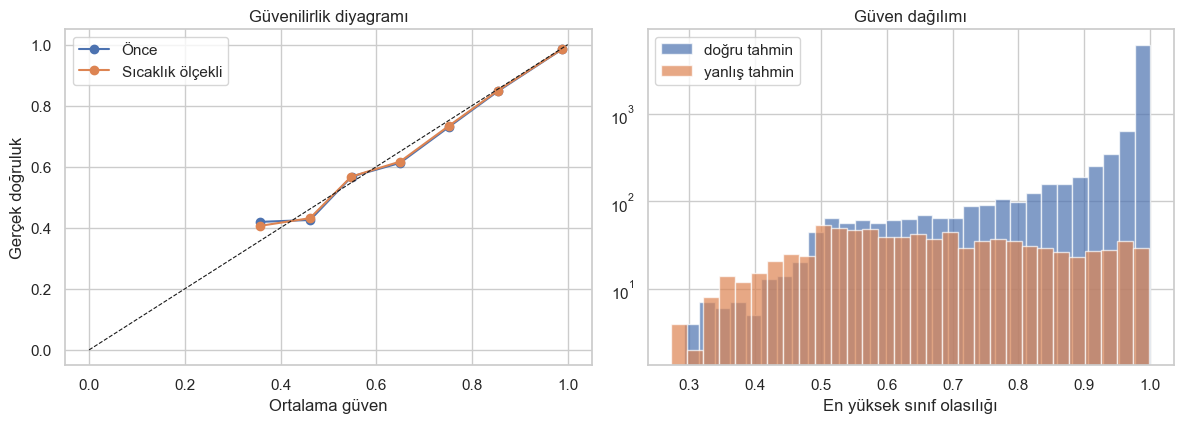

In [11]:
from scipy.optimize import minimize_scalar
def ece(prob, y, n=10):
    conf = prob.max(1); pred = prob.argmax(1); acc = pred == y; e = 0
    for lo in np.linspace(0, 1, n, endpoint=False):
        mk = (conf > lo) & (conf <= lo + 1 / n)
        if mk.any(): e += mk.mean() * abs(acc[mk].mean() - conf[mk].mean())
    return e
def sicaklik(prob, T):
    z = np.log(np.clip(prob, 1e-9, 1)) / T; z -= z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
en_idx = int(np.argmax([accuracy_score(yte, o.argmax(1)) for o in TAHMIN[EN + "|hepsi"]])); en_model = MODELLER[EN][en_idx]
pva = en_model.predict(Xva_n, batch_size=512, verbose=0)
T = minimize_scalar(lambda t: -np.log(np.clip(sicaklik(pva, t)[np.arange(len(yva)), yva], 1e-9, 1)).mean(), bounds=(.3, 3), method="bounded").x
ece_once, ece_sonra = ece(TAHMIN[EN], yte), ece(sicaklik(TAHMIN[EN], T), yte)
print(f"T = {T:.2f} | ECE önce = {ece_once:.4f}, sonra = {ece_sonra:.4f}")
conf = TAHMIN[EN].max(1); dogru = p_en == yte
M["kalibrasyon"] = dict(T=float(T), ece_once=float(ece_once), ece_sonra=float(ece_sonra))
esikler = [.5, .7, .9, .95, .99]; M["guven_tablosu"] = [dict(esik=t_, kapsama=float((conf >= t_).mean()), dogruluk=float(dogru[conf >= t_].mean())) for t_ in esikler]
display(pd.DataFrame(M["guven_tablosu"]).round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for pr_, ad in ((TAHMIN[EN], "Önce"), (sicaklik(TAHMIN[EN], T), "Sıcaklık ölçekli")):
    cf, pd_ = pr_.max(1), pr_.argmax(1) == yte; bins = np.linspace(0, 1, 11); mid, acc_ = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mk = (cf > lo) & (cf <= hi)
        if mk.sum() > 10: mid.append(cf[mk].mean()); acc_.append(pd_[mk].mean())
    ax[0].plot(mid, acc_, "o-", label=ad)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("Güvenilirlik diyagramı"); ax[0].set_xlabel("Ortalama güven"); ax[0].set_ylabel("Gerçek doğruluk"); ax[0].legend()
ax[1].hist(conf[dogru], bins=30, alpha=.7, label="doğru tahmin"); ax[1].hist(conf[~dogru], bins=30, alpha=.7, label="yanlış tahmin"); ax[1].set_yscale("log"); ax[1].set_title("Güven dağılımı"); ax[1].set_xlabel("En yüksek sınıf olasılığı"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/kalibrasyon.png", dpi=150); plt.show()

## 10. Hata Analizi ve Grad-CAM
En çok yanlış yapılan örnekler ve modelin bu kararları verirken **hangi bölgelere baktığı** (Grad-CAM) incelenir.

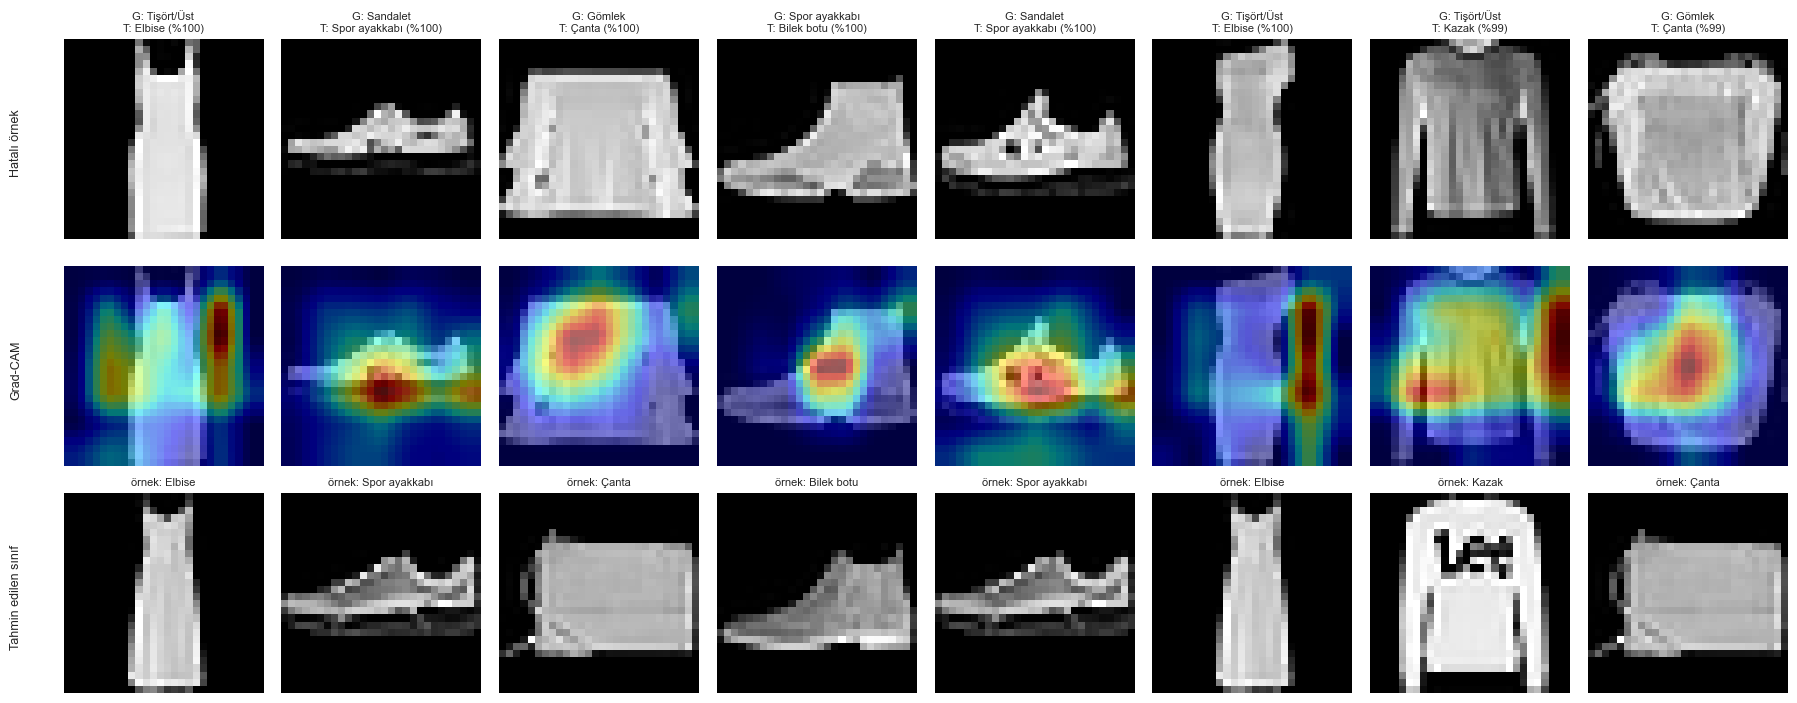

Gömlek           0.312
Ceket            0.128
Tişört/Üst       0.126
Elbise           0.092
Kazak            0.084
Bilek botu       0.068
Sandalet         0.042
Pantolon         0.022
Spor ayakkabı    0.009
Çanta            0.007
dtype: float64


In [12]:
yanlis = np.where(~dogru)[0]; guvenli_yanlis = yanlis[np.argsort(-conf[yanlis])][:8]
son = en_model.get_layer("b3_relu2")
gm = keras.Model(en_model.inputs, [son.output, en_model.output])
def gradcam(x):
    with tf.GradientTape() as tape:
        fm, pred = gm(x[None], training=False); k = tf.argmax(pred[0]); skor = pred[:, k]
    g = tape.gradient(skor, fm); w = tf.reduce_mean(g, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * fm, -1))[0].numpy(); cam = cam / (cam.max() + 1e-9)
    return np.array(keras.ops.image.resize(cam[None, ..., None], (28, 28)))[0, ..., 0]
fig, ax = plt.subplots(3, 8, figsize=(18, 7.2))
for i, k in enumerate(guvenli_yanlis):
    cam = gradcam(Xte_n[k]); ax[0, i].imshow(Xte[k], cmap="gray"); ax[0, i].set_title(f"G: {SINIF[yte[k]]}\nT: {SINIF[p_en[k]]} (%{conf[k]*100:.0f})", fontsize=8)
    ax[1, i].imshow(Xte[k], cmap="gray"); ax[1, i].imshow(cam, cmap="jet", alpha=.5)
    d_ = np.where(yte == p_en[k])[0][0]; ax[2, i].imshow(Xte[d_], cmap="gray"); ax[2, i].set_title(f"örnek: {SINIF[p_en[k]]}", fontsize=8)
for a in ax.ravel(): a.axis("off")
ax[0, 0].text(-8, 14, "Hatalı örnek", rotation=90, va="center", fontsize=9); ax[1, 0].text(-8, 14, "Grad-CAM", rotation=90, va="center", fontsize=9); ax[2, 0].text(-8, 14, "Tahmin edilen sınıf", rotation=90, va="center", fontsize=9)
plt.tight_layout(); plt.savefig("figures/hatalar_gradcam.png", dpi=150); plt.show()
sinif_hata = pd.Series(1 - np.diag(cm) / cm.sum(1), index=SINIF).sort_values(ascending=False); print(sinif_hata.round(3)); M["sinif_hata"] = sinif_hata.round(4).to_dict()
M["yanlis_sayisi"] = int(len(yanlis)); M["yanlis_ort_guven"] = float(conf[yanlis].mean()); M["dogru_ort_guven"] = float(conf[dogru].mean())

In [13]:
en_model.save("fashion_cnn.keras"); json.dump(M, open("metrics.json", "w"), ensure_ascii=False, indent=1, default=float)
print("kaydedildi")

kaydedildi


## 11. Sonuç
Yorum ve değerlendirme rapor dosyasında (`Rapor.docx`).